Here, I am running a basic correlation between all variables included in our dataset and cancer incidence, to understand what we can learn without the help of more sophisticated modeling approaches and inform hypotheses

In [1]:
import pandas as pd 
import numpy as np
import os 

os.chdir("/Users/elise/Downloads")

In [2]:
#then, I will import my dataset
data_all = pd.read_csv("/Users/elise/Downloads/californiahealthmaps_alldata/californiahealthmaps_mssa_all.csv")

# Preview the first 5 rows
print(data_all.head())

data_all['Cancer'].unique()

  AreaID Counties                 Cities  \
0    1.1  Alameda              Livermore   
1    1.2  Alameda  Livermore, Pleasanton   
2     10    Butte               Oroville   
3    100    Modoc                    NaN   
4    102     Mono                    NaN   

                                                 URL   Sex   Cancer Years  \
0  https://www.californiahealthmaps.org?areatype=...  Male  AllSite  05yr   
1  https://www.californiahealthmaps.org?areatype=...  Male  AllSite  05yr   
2  https://www.californiahealthmaps.org?areatype=...  Male  AllSite  05yr   
3  https://www.californiahealthmaps.org?areatype=...  Male  AllSite  05yr   
4  https://www.californiahealthmaps.org?areatype=...  Male  AllSite  05yr   

     PopTot   AAIR    LCI  ...  PerWhite  PerBlack  PerAsian  PerHispanic  \
0  147499.0  432.2  398.9  ...      57.9       3.2      12.6         25.9   
1  101320.0  465.1  422.3  ...      57.8       3.2      21.3         17.4   
2  118159.0  547.0  509.2  ...      66.1 

array(['AllSite', 'breas', 'CRC', 'Kidney', 'Liver', 'Lung', 'Lymph',
       'Mela', 'Pancreas', 'Prostate', 'Thyroid', 'Breast', 'Uterine',
       'Urinary'], dtype=object)

In [3]:
import pandas as pd

sex_options = ["Male", "Female", "Both"]
cancer_options = data_all['Cancer'].unique()
year_options = ["05yr", "10yr"]

cols = ['AAIR', 'QNSES', 'PopTot', 'PerRural', 'PerUninsured', 'PerForeignBorn',
        'PerWhite', 'PerBlack', 'PerAsian', 'PerHispanic', 'PerDocVisit',
        'PerMenPrev', 'PerWomenPrev', 'PerMammo', 'PerCervical', 'PerFOBT']

results = {}   # results[year][sex][cancer] -> Series of correlations
rows = []      # flat version for easy viewing/exporting

for year in year_options:
    results[year] = {}
    for sex in sex_options:
        results[year][sex] = {}
        for cancer in cancer_options:
            subset = data_all[
                (data_all['Years'] == year) &
                (data_all['Sex'] == sex) &
                (data_all['Cancer'] == cancer)
            ][cols].dropna(subset=['PopTot', 'AAIR'])

            if len(subset) < 3:  # not enough data to correlate
                continue

            X = subset.drop(columns='AAIR')
            y = subset['AAIR']

            # Spearman rank correlation (swap in 'pearson' or 'kendall' if needed)
            corr = X.corrwith(y, method='spearman')
            results[year][sex][cancer] = corr

            df = corr.rename('rho').rename_axis('Variable').reset_index()
            df['Years'], df['Sex'], df['Cancer'] = year, sex, cancer
            df['n'] = len(subset)
            rows.append(df)

results_df = pd.concat(rows, ignore_index=True)
print(results_df.head(20))

# Wide table: one row per Years/Sex/Cancer, one column per variable
results_wide = results_df.pivot_table(index=['Years', 'Sex', 'Cancer'],
                                      columns='Variable', values='rho')

print(results_wide.head())

          Variable       rho Years   Sex   Cancer    n
0            QNSES  0.283706  05yr  Male  AllSite  507
1           PopTot -0.080378  05yr  Male  AllSite  507
2         PerRural  0.243943  05yr  Male  AllSite  507
3     PerUninsured -0.322219  05yr  Male  AllSite  507
4   PerForeignBorn -0.468920  05yr  Male  AllSite  507
5         PerWhite  0.454847  05yr  Male  AllSite  507
6         PerBlack -0.054033  05yr  Male  AllSite  507
7         PerAsian -0.069174  05yr  Male  AllSite  507
8      PerHispanic -0.301355  05yr  Male  AllSite  507
9      PerDocVisit  0.179374  05yr  Male  AllSite  507
10      PerMenPrev  0.380775  05yr  Male  AllSite  507
11    PerWomenPrev  0.408256  05yr  Male  AllSite  507
12        PerMammo -0.069966  05yr  Male  AllSite  507
13     PerCervical  0.479314  05yr  Male  AllSite  507
14         PerFOBT  0.329529  05yr  Male  AllSite  507
15           QNSES -0.334933  05yr  Male      CRC  435
16          PopTot -0.081382  05yr  Male      CRC  435
17        

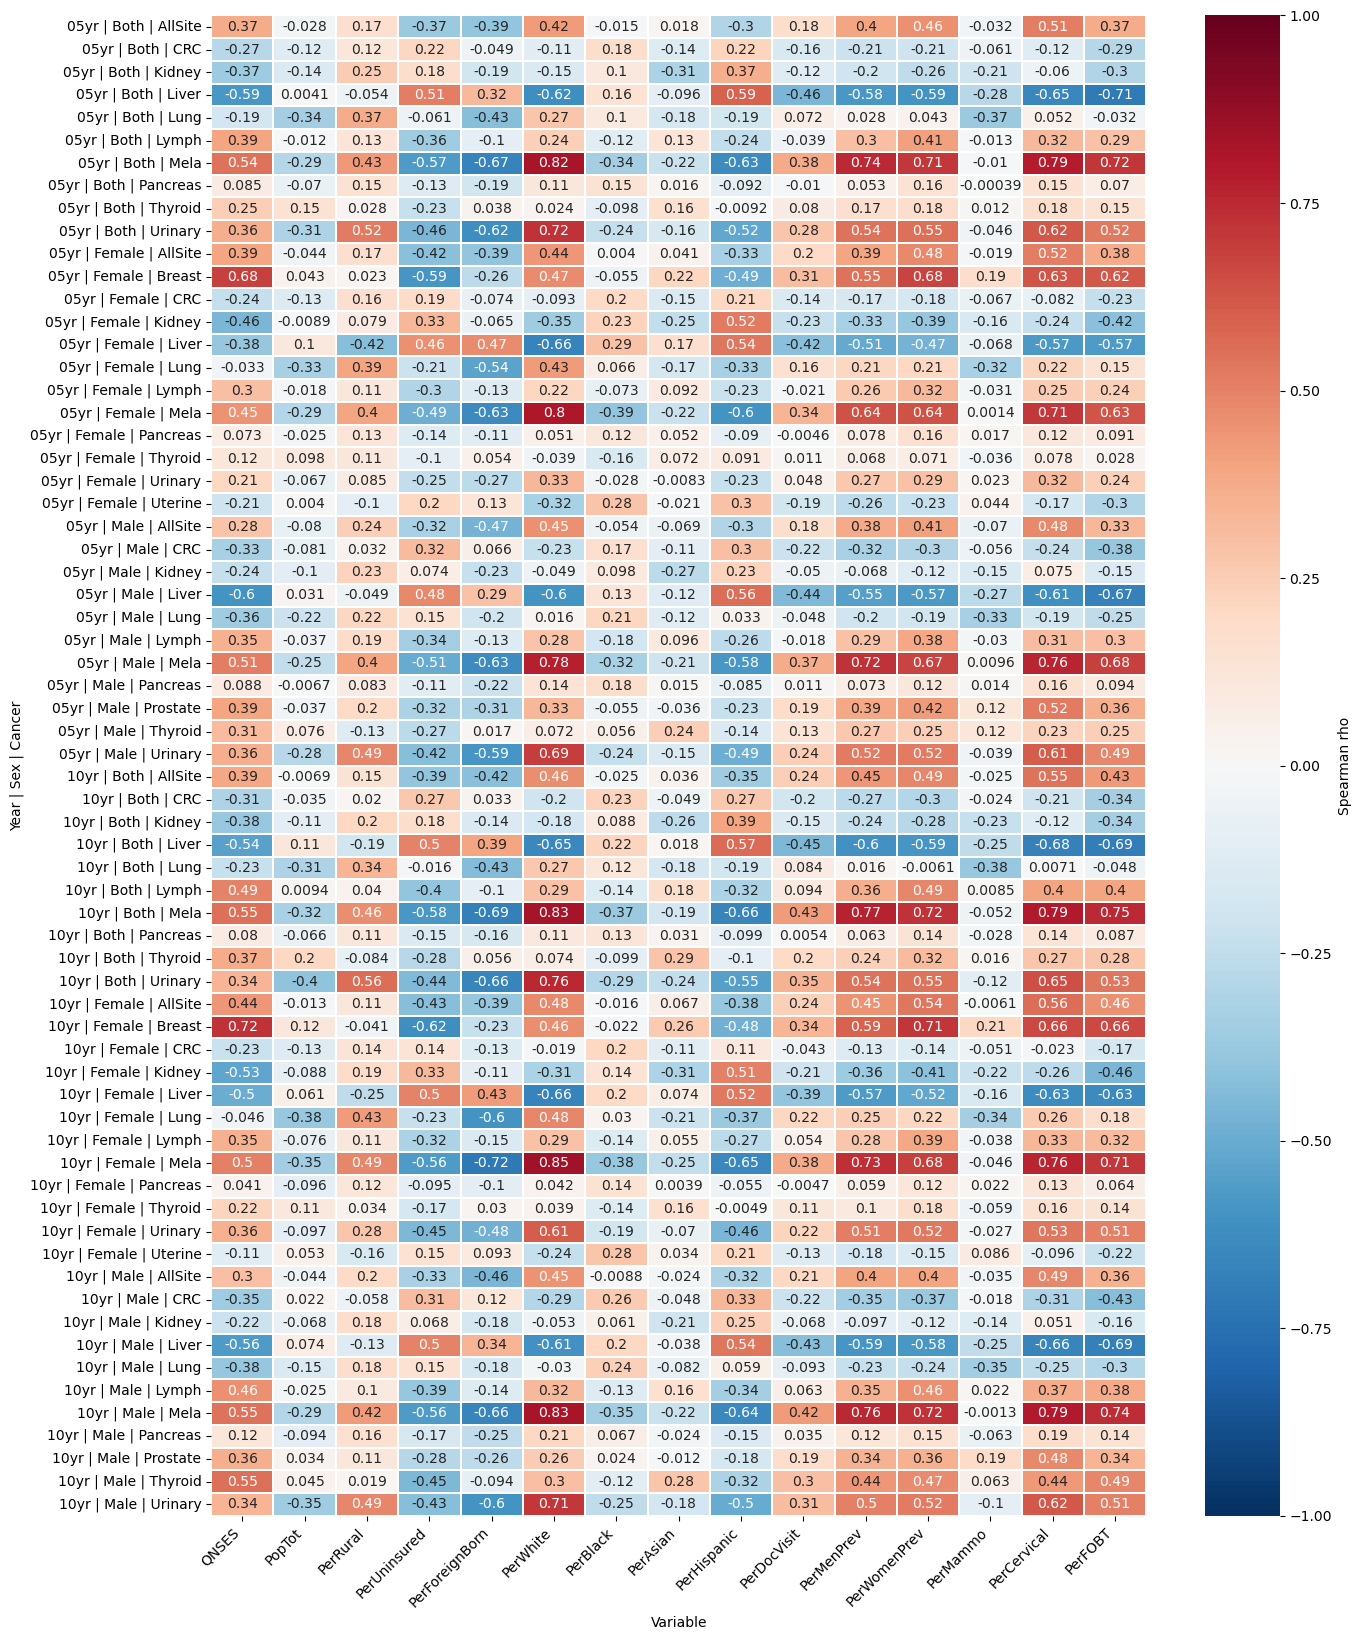

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

# Rows = Years/Sex/Cancer combos, columns = variables
heat = results_wide.copy()
heat.index = [f"{y} | {s} | {c}" for y, s, c in heat.index]

# Optional: order columns as in your original list
var_order = [c for c in cols if c != 'AAIR']
heat = heat[var_order]

fig_height = max(6, 0.25 * len(heat))   # scale height with number of rows
fig, ax = plt.subplots(figsize=(14, fig_height))

sns.heatmap(
    heat,
    cmap="RdBu_r",        # red = positive, blue = negative
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.3,
    linecolor="white",
    annot=True,          # set True (with fmt=".2f") if you have few rows
    cbar_kws={"label": "Spearman rho"},
    ax=ax,
)

ax.set_xlabel("Variable")
ax.set_ylabel("Year | Sex | Cancer")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

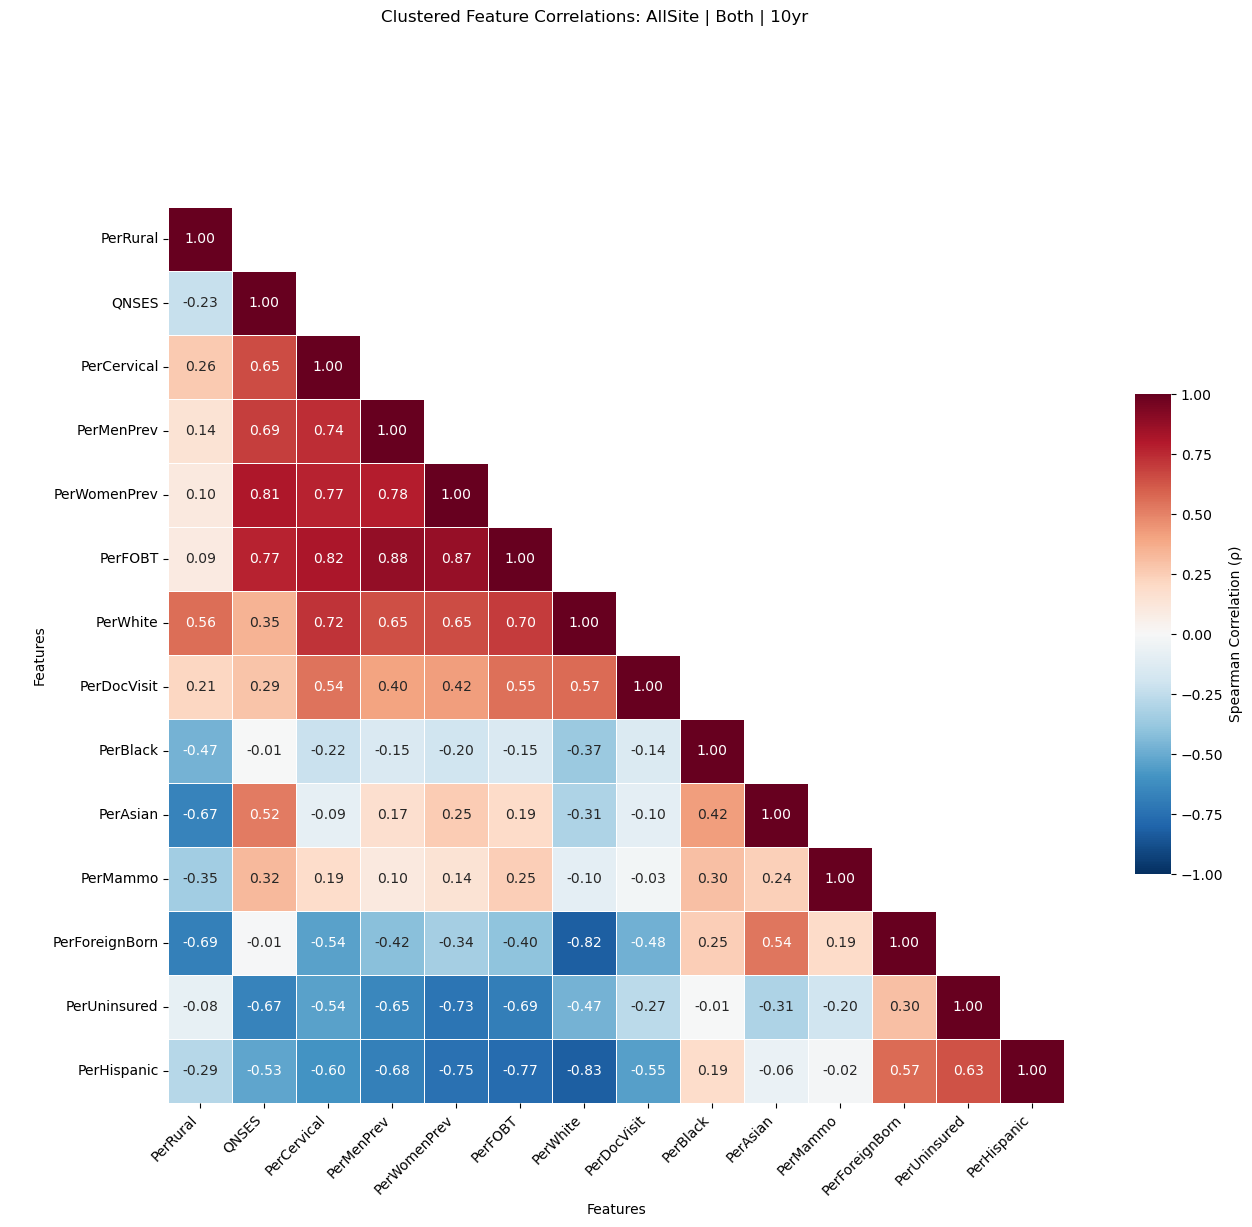

In [13]:

from scipy.stats import spearmanr
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os

df = data_all

all_features = [
    "QNSES", "PerRural", "PerUninsured", "PerForeignBorn",
    "PerWhite", "PerBlack", "PerAsian", "PerHispanic",
    "PerDocVisit", "PerMenPrev", "PerWomenPrev", "PerCervical", "PerFOBT", "PerMammo"]

#Figured out a little late in the game that the features are always the same because the same areas are features for every cancer, so only creating one corr plot
sex_options = ["Both"]
year_options = ["5yr", "10yr"]
cancer_options = ["AllSite"]

for cancer in cancer_options:
    for sex in sex_options:
        for years in year_options:

            cancer_df = df[
                (df.Cancer == cancer) &
                (df.Sex == sex) &
                (df.Years == years)
            ]

            # Keep only complete observations
            corr_df = cancer_df[all_features].dropna()

            if len(corr_df) < 100:
                continue

            # Calculate pairwise Spearman correlations

            # Calculate Spearman correlation matrix
            corr = corr_df.corr(method="spearman")

            # First, generate clustering to determine variable order
            g = sns.clustermap(
                corr,
                method="average",
                metric="euclidean",
                cmap="RdBu_r",
                center=0,
                vmin=-1,
                vmax=1,
                figsize=(12, 12),
                annot=False,
                cbar_kws={"label": "Spearman Correlation (ρ)"}
            )

            # Get clustered variable order
            row_order = g.dendrogram_row.reordered_ind
            col_order = g.dendrogram_col.reordered_ind

            # Reorder correlation matrix
            corr_clustered = corr.iloc[row_order, col_order]

            # Create upper triangle mask
            mask = np.triu(
                np.ones_like(corr_clustered, dtype=bool),
                k=1
            )

            # Remove initial clustermap
            plt.close(g.fig)

            # Generate final triangular clustered heatmap
            g = sns.clustermap(
                corr_clustered,
                row_cluster=False,
                col_cluster=False,
                mask=mask,
                cmap="RdBu_r",
                center=0,
                vmin=-1,
                vmax=1,
                annot=True,
                fmt=".2f",
                linewidths=0.5,
                figsize=(12, 12),
                dendrogram_ratio=(0.15, 0.15),
                cbar_kws={"label": "Spearman Correlation (ρ)"}
            )

            # Variable labels
            g.ax_heatmap.set_xticklabels(
                g.ax_heatmap.get_xticklabels(),
                rotation=45,
                ha="right"
            )

            g.ax_heatmap.set_yticklabels(
                g.ax_heatmap.get_yticklabels(),
                rotation=0
            )

            g.ax_heatmap.set_xlabel("Features")
            g.ax_heatmap.set_ylabel("Features")
            
            # Move row dendrogram to the right
            g.ax_row_dendrogram.yaxis.set_ticks_position("right")
            g.ax_row_dendrogram.yaxis.set_label_position("right")

            # Put feature labels on the left side of the heatmap
            g.ax_heatmap.yaxis.set_ticks_position("left")
            g.ax_heatmap.yaxis.set_label_position("left")

            g.ax_heatmap.set_yticklabels(
                g.ax_heatmap.get_yticklabels(),
                rotation=0
            )

            g.ax_heatmap.set_ylabel("Features")
            g.ax_heatmap.set_xlabel("Features")
            
            g.cax.set_position([0.95, 0.3, 0.03, 0.4])

            g.fig.suptitle(
                f"Clustered Feature Correlations: {cancer} | {sex} | {years}",
                y=1.02
            )

            plt.savefig(
                f"CRC_kidney_thyroid/"
                f"clustered_corr_{cancer}_{sex}_{years}.png",
                dpi=200,
                bbox_inches="tight"
            )

            plt.show()
            plt.close()
